# 2 · Your first classifier

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/02_first_classifier.ipynb)

In tutorial 1 we built a graph of twelve sentences. Now we use the
**20 Newsgroups** benchmark (one of the datasets of Yao et al., 2019 and
Pereira & de Castro, DCAI 2022) and go all the way to test accuracy:

1. **Download** it and write the Text4GCN input files.
2. **Preprocess** it with `TextPipeline`.
3. **Build the graph** with `Frequency.tfidf()`.
4. **Train and evaluate** a GCN with `GNN.fit()`.

> **Runtime:** with the 4-category subset (~3.6k documents) this takes about 2.5 min on a T4 GPU
> and needs about 4 GB of RAM. Almost all of it is building the graph (about 2 min), which runs on
> the CPU; a GPU speeds up only the training, which takes several times longer on CPU.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | **Your first classifier** | How do I go from raw text to test accuracy? |
| 3 | Choosing a graph builder | How should words be connected? |
| 4 | Refining the graph | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

In [2]:
import shutil
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

import text4gcn
from text4gcn import GNN, Builder, TextPipeline
from text4gcn.builder import Frequency
from text4gcn.datasets import twenty_newsgroups
from text4gcn.utils import check_pytorch_installation, get_device_manager

In [3]:
print("text4gcn:", text4gcn.__version__)
print(check_pytorch_installation())
print(get_device_manager().get_device_info())

text4gcn: 2.0.0rc2
{'torch_version': '2.11.0+cu130', 'cuda_available': True, 'cuda_version': '13.0'}
{'device': 'cuda', 'type': 'cuda', 'is_cuda': True, 'is_cpu': False, 'cuda_version': '13.0', 'gpu_name': 'Tesla T4', 'gpu_memory': 15637086208, 'gpu_memory_gb': 15.637086208}


## Configuration

The whole corpus, documents **and** vocabulary, becomes a single graph. The
full 20NG (18,846 posts) therefore needs a large GPU. We use the four
categories of the classic scikit-learn text tutorial. To scale up, add
categories or set `CATEGORIES = None`.

In [4]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

## 1. Download and write the input files

`twenty_newsgroups()` downloads the corpus with scikit-learn (already a
dependency) and keeps the official train/test split. It strips e-mail headers,
signatures and quoted replies, so the model learns from the message body, and
it drops posts left with fewer than 5 words. It then calls `save_corpus()`,
which writes the two files every Text4GCN dataset needs:

| File | One line per document |
|---|---|
| `<name>.txt` | the text, on a single line |
| `<name>.meta` | `<doc id>\t<train|test>\t<label>` |

We start from an empty folder: `TextPipeline` rewrites its own files, but outputs left by an older
run, such as a graph built for another vocabulary, would stay next to them.

In [5]:
shutil.rmtree(DATA_DIR, ignore_errors=True)
txt_path, meta_path = twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)

meta = pd.read_csv(meta_path, sep="\t", names=["id", "split", "label"])
meta.pivot_table(index="label", columns="split", values="id", aggfunc="count", margins=True)

split,test,train,All
label,,,
alt.atheism,309,464,773
comp.graphics,383,564,947
sci.med,379,575,954
soc.religion.christian,384,589,973
All,1455,2192,3647


In [6]:
print(txt_path.read_text(encoding="utf-8").splitlines()[0][:400])

Does anyone know of a good way (standard PC application/PD utility) to convert tif/img/tga files into LaserJet III format. We would also like to do the same, converting to HPGL (HP plotter) files. Please email any response. Is this the correct group? Thanks in advance. Michael.


## 2. Preprocess

`execute()` writes three folders next to the input files:

| Folder | Content |
|---|---|
| `<name>.cleaned/` | text lower-cased and tokenized, without stop words and words seen fewer than `rare_count` times |
| `<name>.shuffled/` | documents shuffled with `seed`, the vocabulary, the train/test ids |
| `<name>.node_features/` | feature and label matrices; `validation_ratio` of the training documents is held out for validation |

`validation_ratio` is the **only** place where the validation split is defined.

In [7]:
TextPipeline(
    dataset_name=NAME,
    dataset_path=DATA_DIR,
    rare_count=5,
    language="english",
    seed=SEED,
).execute(validation_ratio=0.10)

text4gcn · TextPipeline("20NG4") · language english · validation 10%
  ✓ clean     3,647 documents · 10,890 words kept (rare_count=5)  (0.8 s)
  ✓ shuffle   train 2,192 · test 1,455 documents (seed 1234)  (0.1 s)
  ✓ words     10,890 words · 9,179 with a WordNet definition  (5.4 s)
  ✓ features  train 1,973 · validation 219 · test 1,455 documents · 4 classes  (1.6 s)


In [8]:
vocab = (DATA_DIR / f"{NAME}.shuffled" / f"{NAME}.vocab").read_text(encoding="utf-8").split()
print(f"vocabulary: {len(vocab):,} words -> graph with {len(meta) + len(vocab):,} nodes")

vocabulary: 10,890 words -> graph with 14,537 nodes


## 3. Build the graph

The TextGCN graph has PMI word–word edges and TF-IDF document–word edges (see
tutorial 1). `GraphBuildStats` reports its size.

In [9]:
stats = Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)
stats

text4gcn · Frequency.tfidf("20NG4") · window 20
  ✓ graph     14,537 nodes · 4.53 M edges (4.26 M word–word) · density 2.15% · 52.0 MiB  (2m02s)


GraphBuildStats(builder='frequency.tfidf', dataset='20NG4', nodes=14,537, edges=4,534,779, word_word=4,258,440, density=2.15%, size='52.0 MiB')

## 4. Train and evaluate

`GNN` loads the features and the graph and trains a 2-layer GCN with the
protocol of the paper: hidden size 200, dropout 0.5 and learning rate 0.02. Training
stops early when the validation loss rises above its mean over the previous 10 epochs
(the criterion of the reference TextGCN code). It uses CUDA when available. When training
stops, the weights with the best validation loss are restored and evaluated on
the test documents.

In [10]:
result = GNN(
    dataset_name=NAME,
    dataset_path=DATA_DIR,
    log_dir=LOG_DIR,
    builder=Builder.Tfidf,      # the graph built in step 3
    seed=SEED,
).fit()

text4gcn · GNN("20NG4") · frequency.tfidf · cuda (Tesla T4) · seed 1234
  graph     14,537 nodes: 1,973 train · 219 validation · 1,455 test documents + 10,890 words
  model     GCN 14,537 → 200 → 4 · 2.91 M parameters · dropout 0.5 · lr 0.02
  ✓ train     68 epochs (early stop) · best epoch 64 (val_loss 1.3679, val_acc 93.6%)  (6.8 s)                            
  ✓ test      accuracy 86.7% · macro-F1 86.1% · loss 1.2910 · 1,455 documents  (<0.1 s)

                     class  precision  recall    f1  support
    soc.religion.christian      0.798   0.885 0.840      384
                   sci.med      0.934   0.889 0.911      379
               alt.atheism      0.804   0.718 0.759      309
             comp.graphics      0.923   0.945 0.934      383

  model     logs/20261018-002516776.pth


In [11]:
print(f"test accuracy : {result.test_accuracy:.4f}")
print(f"epochs trained: {result.epochs_trained}")
print(f"checkpoint    : {result.model_path}")

test accuracy : 0.8667
epochs trained: 68
checkpoint    : logs/20261018-002516776.pth


Training curves are saved in `log_dir`.

The loss values stay close to $\ln(4) \approx 1.39$, and the validation curve looks
almost flat. This is expected: as in the reference TextGCN implementation, the
cross-entropy is averaged over **all** nodes, and the rows outside each split
have zeroed logits. Accuracy is the curve to read.

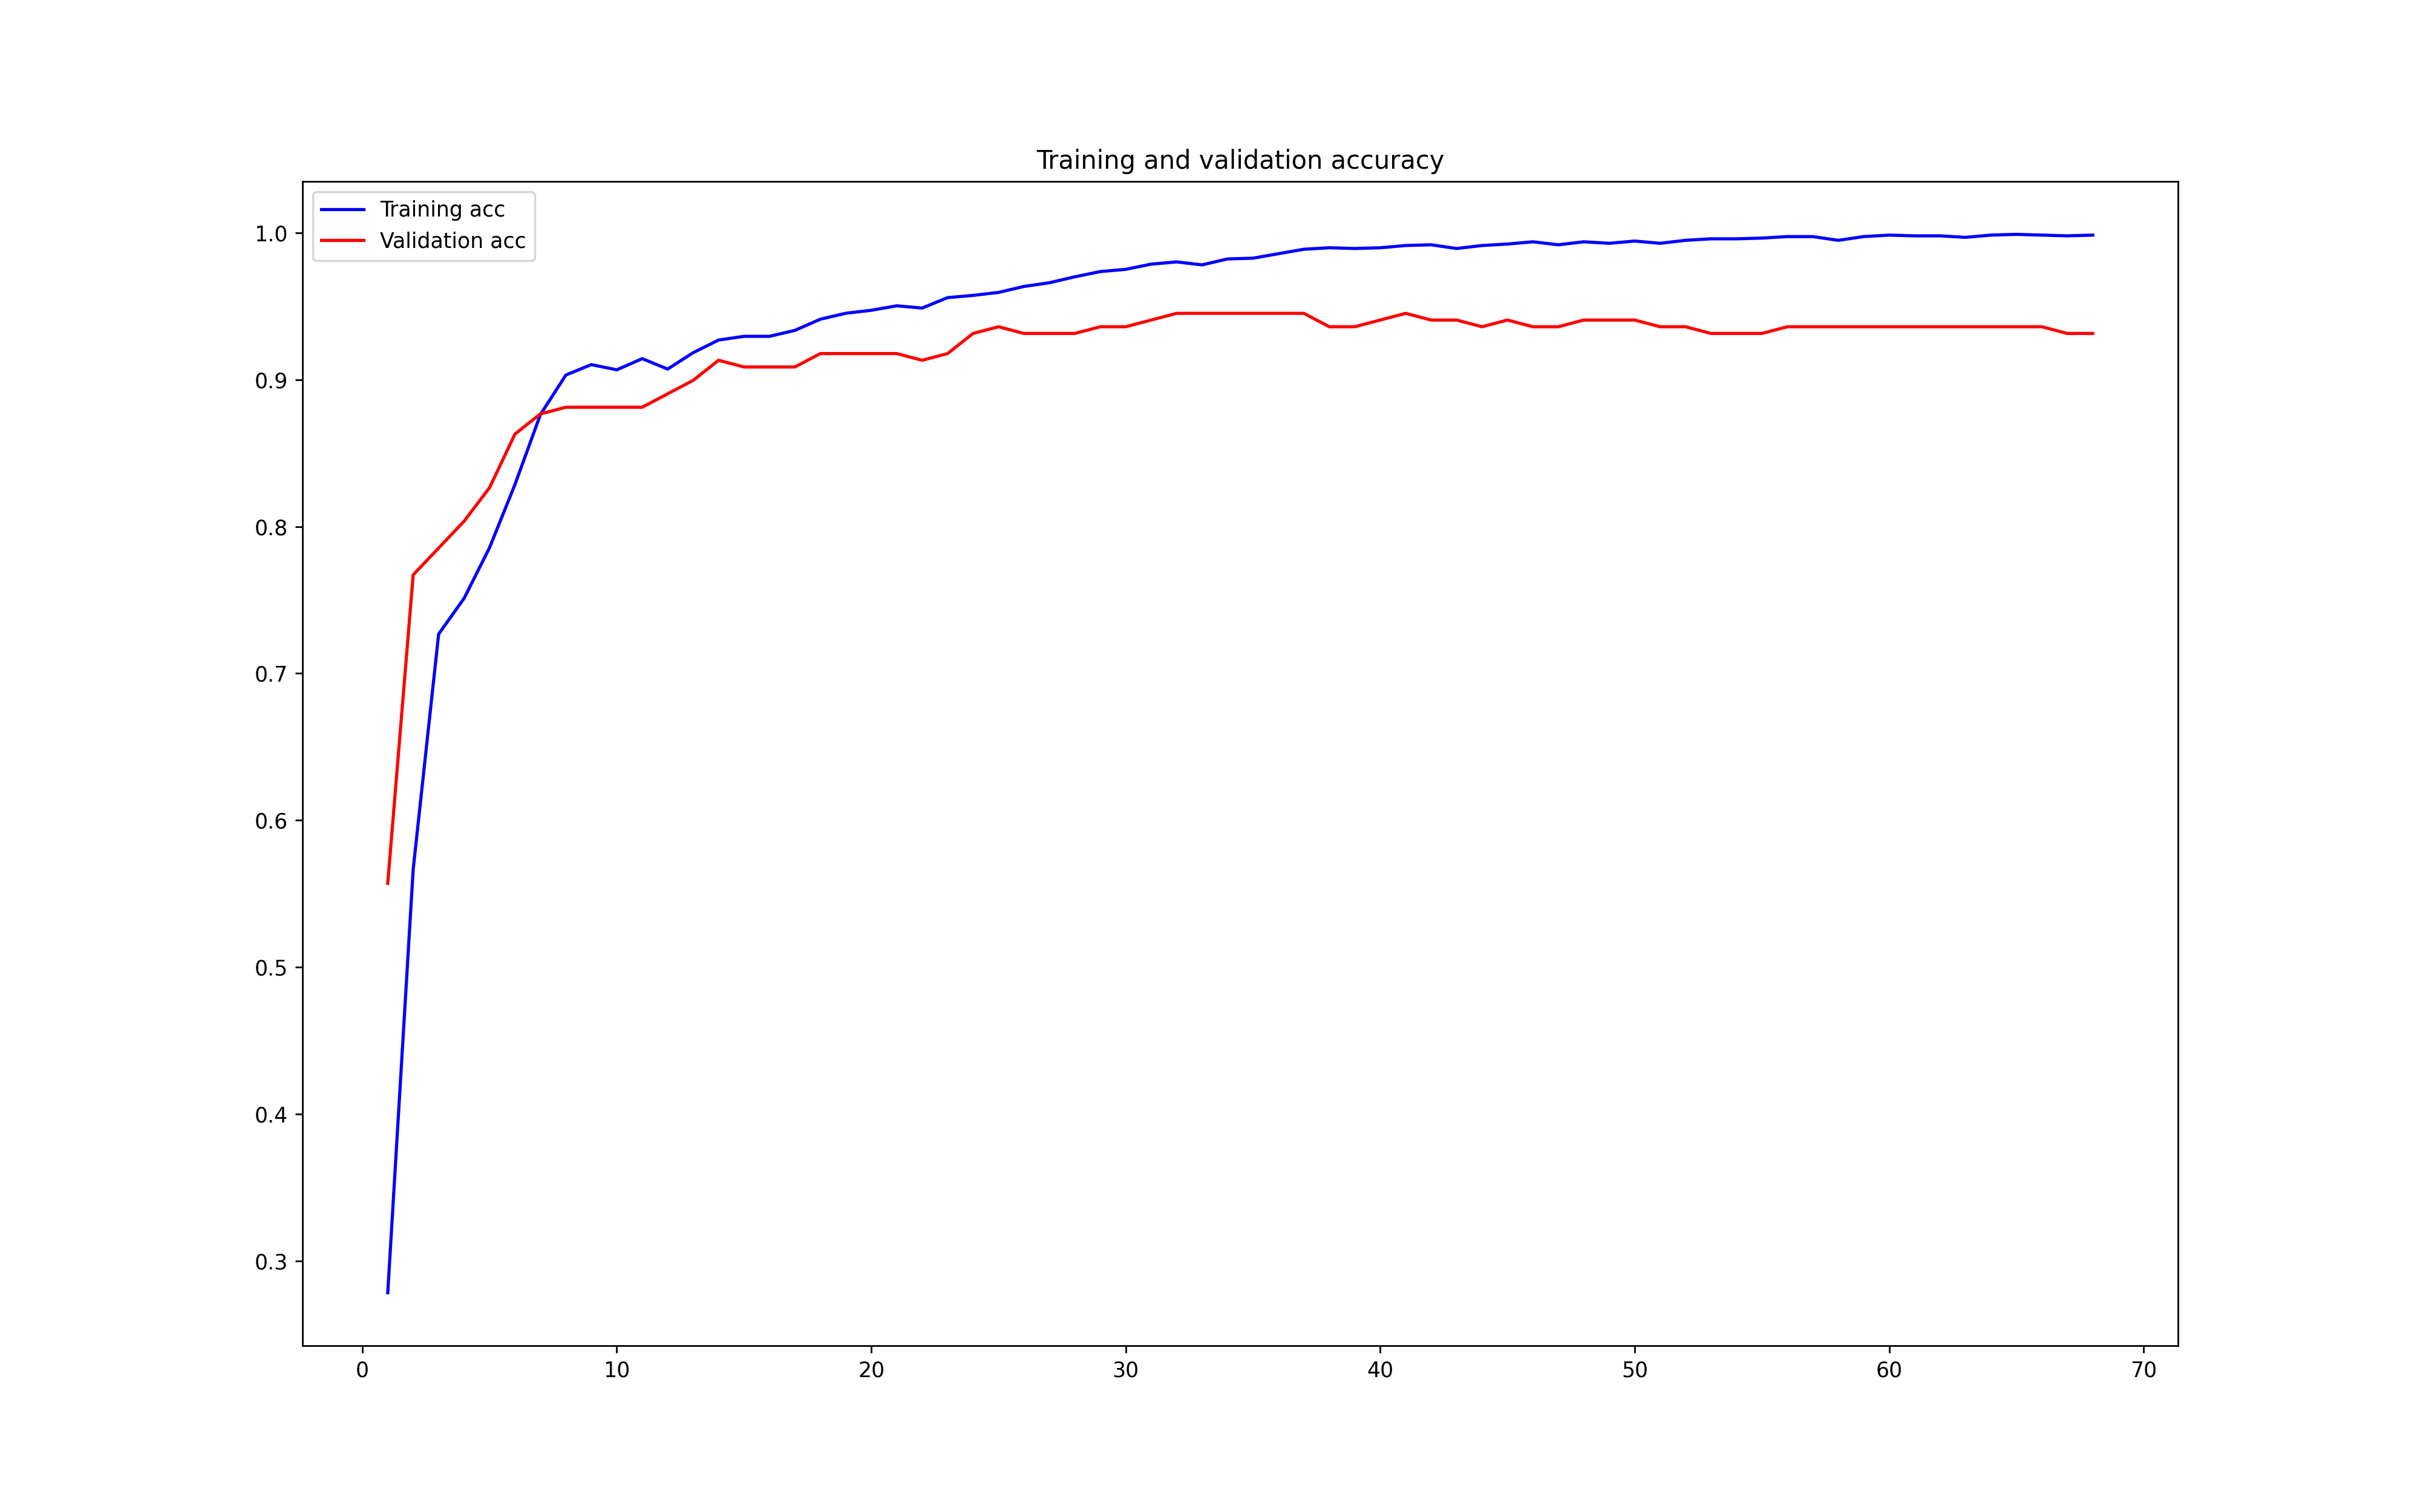

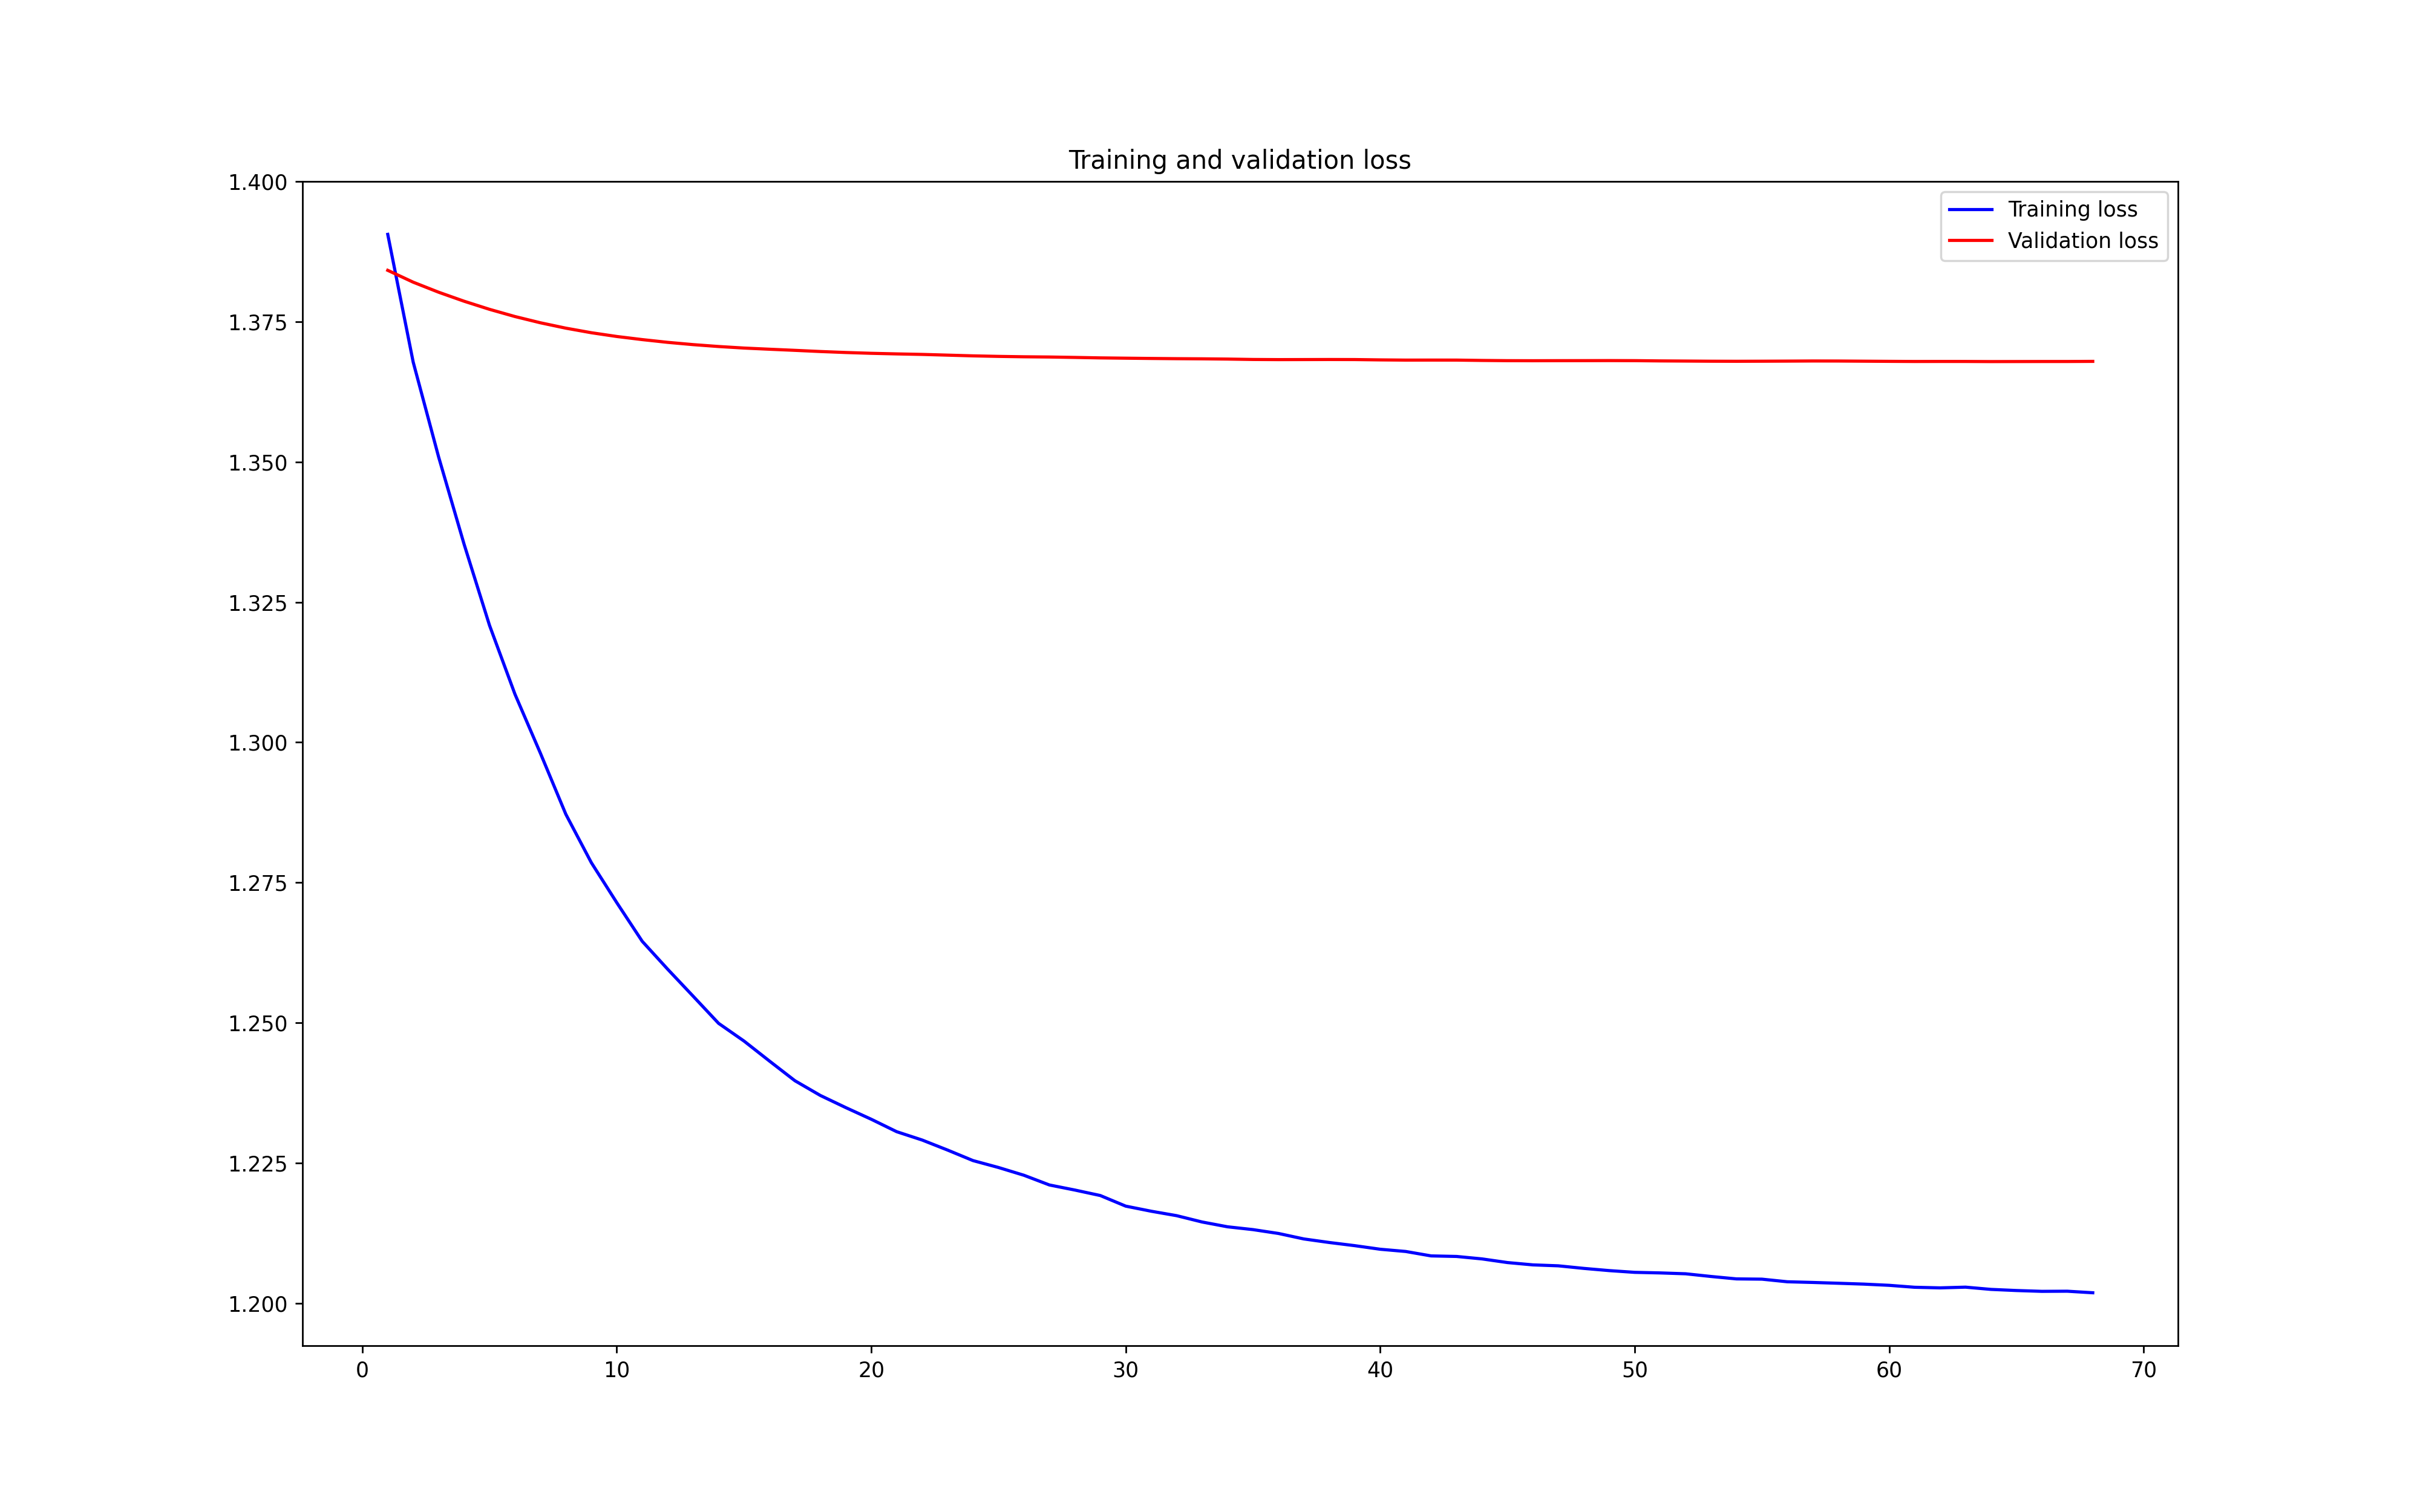

In [12]:
display(Image(LOG_DIR / "metrics-acc.png"), Image(LOG_DIR / "metrics-loss.png"))

## What's next

The graph above has millions of edges, most of them word–word PMI pairs. Do we
need all of them?

**Next:** [3 · Choosing a graph builder](https://vitormeriat.github.io/text4gcn/tutorials/03_choosing_a_graph_builder/) builds the graph in other
ways and compares size, speed and accuracy.